<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Dataset 1: XOR-Style Loan Dataset ===
Analytical Gradient (W1[0,0]): 0.0013440404
Numerical  Gradient (W1[0,0]): 0.0013440404
Absolute Difference          : 1.74e-12 -> PASSED
Final XOR Loss: 0.0537 | Accuracy: 98.00%



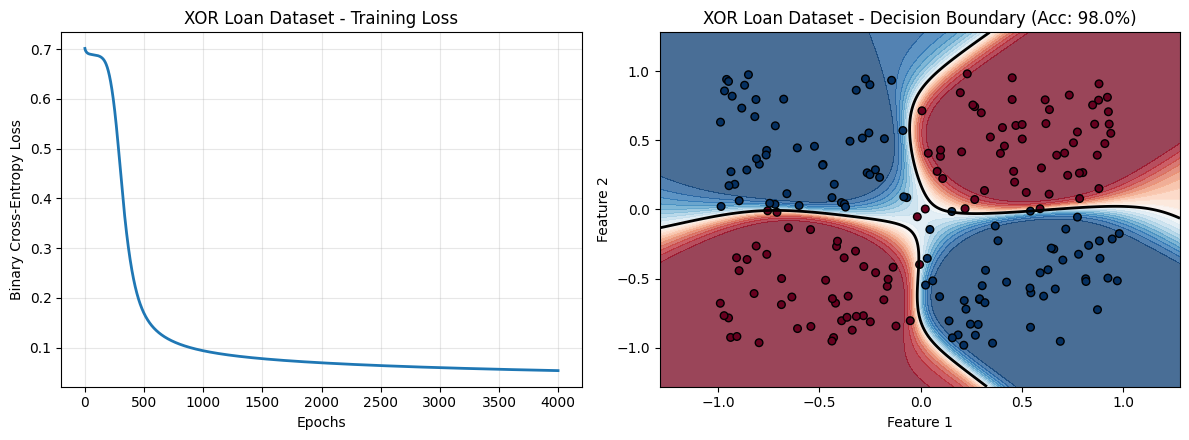

=== Dataset 2: Two-Moons Customer Segmentation ===
Analytical Gradient (W1[0,0]): -0.0061428549
Numerical  Gradient (W1[0,0]): -0.0061428549
Absolute Difference          : 7.76e-12 -> PASSED
Final Two-Moons Loss: 0.0062 | Accuracy: 100.00%


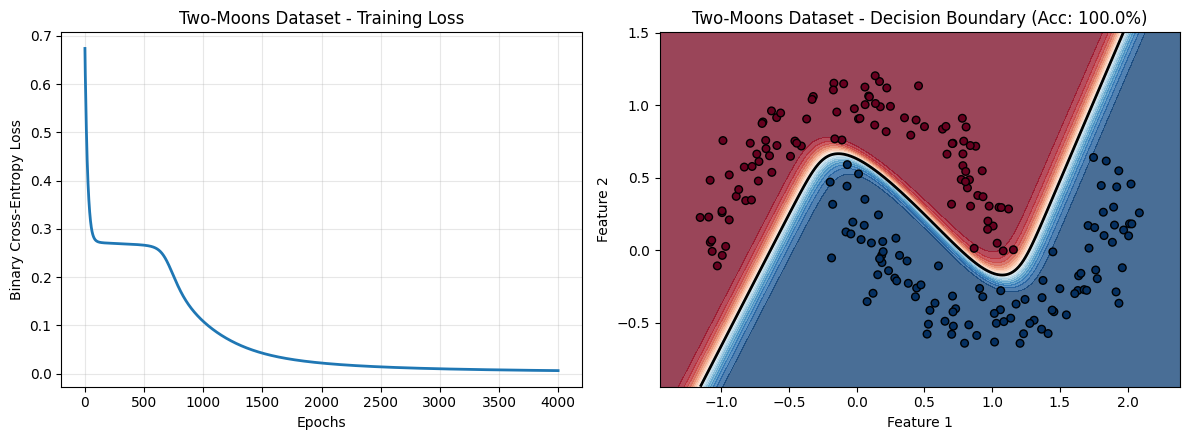

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ==========================================
# Helper: Datasets (XOR & Two-Moons in NumPy)
# ==========================================
def make_xor_loan_data(n_samples=200):
    X = np.random.uniform(-1, 1, (n_samples, 2))
    y = ((X[:, 0] > 0) ^ (X[:, 1] > 0)).astype(float).reshape(-1, 1)
    return X, y

def make_two_moons(n_samples=200, noise=0.12):
    n = n_samples // 2
    t1 = np.linspace(0, np.pi, n)
    t2 = np.linspace(0, np.pi, n)
    x1 = np.c_[np.cos(t1), np.sin(t1)]
    x2 = np.c_[1 - np.cos(t2), 0.5 - np.sin(t2)]
    X = np.vstack([x1, x2]) + np.random.normal(0, noise, (2 * n, 2))
    y = np.vstack([np.zeros((n, 1)), np.ones((n, 1))])
    return X, y

# ==========================================
# Task 1, 2 & 3: 2-Layer NN (Init, Forward, Backprop)
# ==========================================
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def bce_loss(y_true, y_pred):
    eps = 1e-12
    y_pred = np.clip(y_pred, eps, 1.0 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

class TwoLayerNN:
    def __init__(self, input_dim, hidden_dim, output_dim=1, seed=42):
        rng = np.random.default_rng(seed)
        # Task 1: Weight & bias initialization
        self.W1 = rng.normal(0, np.sqrt(1.0 / input_dim), (input_dim, hidden_dim))
        self.b1 = np.zeros((1, hidden_dim))
        self.W2 = rng.normal(0, np.sqrt(1.0 / hidden_dim), (hidden_dim, output_dim))
        self.b2 = np.zeros((1, output_dim))

    # Task 2: Forward pass with sigmoid activations
    def forward(self, X):
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = sigmoid(self.Z1)
        self.Z2 = self.A1 @ self.W2 + self.b2
        self.A2 = sigmoid(self.Z2)
        return self.A2

    # Task 3: Backward pass using the chain rule
    def backward(self, X, y):
        m = X.shape[0]
        dZ2 = (self.A2 - y) / m                      # dL/dZ2 for BCE + Sigmoid
        dW2 = self.A1.T @ dZ2                        # dL/dW2
        db2 = np.sum(dZ2, axis=0, keepdims=True)     # dL/db2

        dA1 = dZ2 @ self.W2.T                        # dL/dA1
        dZ1 = dA1 * (self.A1 * (1.0 - self.A1))      # dL/dZ1 = dL/dA1 * sigmoid'(Z1)
        dW1 = X.T @ dZ1                              # dL/dW1
        db1 = np.sum(dZ1, axis=0, keepdims=True)     # dL/db1
        return dW1, db1, dW2, db2

    # Task 4: Gradient descent training loop
    def fit(self, X, y, lr=1.0, epochs=3000):
        losses = []
        for _ in range(epochs):
            y_pred = self.forward(X)
            losses.append(bce_loss(y, y_pred))
            dW1, db1, dW2, db2 = self.backward(X, y)
            self.W1 -= lr * dW1
            self.b1 -= lr * db1
            self.W2 -= lr * dW2
            self.b2 -= lr * db2
        return losses

    def predict(self, X):
        return (self.forward(X) >= 0.5).astype(int)

# ==========================================
# Task 5a: Numerical Gradient Verification
# ==========================================
def verify_gradient(model, X, y, eps=1e-5):
    model.forward(X)
    dW1, _, _, _ = model.backward(X, y)
    analytical_grad = dW1[0, 0]

    orig = model.W1[0, 0]
    model.W1[0, 0] = orig + eps
    loss_plus = bce_loss(y, model.forward(X))
    model.W1[0, 0] = orig - eps
    loss_minus = bce_loss(y, model.forward(X))
    model.W1[0, 0] = orig

    numerical_grad = (loss_plus - loss_minus) / (2 * eps)
    diff = abs(analytical_grad - numerical_grad)
    print(f"Analytical Gradient (W1[0,0]): {analytical_grad:.10f}")
    print(f"Numerical  Gradient (W1[0,0]): {numerical_grad:.10f}")
    print(f"Absolute Difference          : {diff:.2e} -> {'PASSED' if diff < 1e-7 else 'FAILED'}")

# ==========================================
# Task 4 & 5b: Train, Plot Loss & Decision Boundary
# ==========================================
def plot_results(model, X, y, losses, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    # Loss curve
    axes[0].plot(losses, color="tab:blue", linewidth=2)
    axes[0].set_title(f"{title} - Training Loss")
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel("Binary Cross-Entropy Loss")
    axes[0].grid(True, alpha=0.3)

    # Non-linear decision boundary
    x_min, x_max = X[:, 0].min() - 0.3, X[:, 0].max() + 0.3
    y_min, y_max = X[:, 1].min() - 0.3, X[:, 1].max() + 0.3
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250),
                         np.linspace(y_min, y_max, 250))
    grid = np.c_[xx.ravel(), yy.ravel()]
    probs = model.forward(grid).reshape(xx.shape)

    axes[1].contourf(xx, yy, probs, levels=20, cmap="RdBu", alpha=0.75)
    axes[1].contour(xx, yy, probs, levels=[0.5], colors="black", linewidths=2)
    axes[1].scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="RdBu", edgecolors="k", s=30)
    acc = np.mean(model.predict(X) == y) * 100
    axes[1].set_title(f"{title} - Decision Boundary (Acc: {acc:.1f}%)")
    axes[1].set_xlabel("Feature 1")
    axes[1].set_ylabel("Feature 2")

    plt.tight_layout()
    plt.show()

# Run on Dataset 1: XOR-Style Loan Dataset
print("=== Dataset 1: XOR-Style Loan Dataset ===")
X_xor, y_xor = make_xor_loan_data(200)
nn_xor = TwoLayerNN(input_dim=2, hidden_dim=8, output_dim=1, seed=42)
verify_gradient(nn_xor, X_xor, y_xor)
losses_xor = nn_xor.fit(X_xor, y_xor, lr=1.5, epochs=4000)
print(f"Final XOR Loss: {losses_xor[-1]:.4f} | Accuracy: {np.mean(nn_xor.predict(X_xor) == y_xor)*100:.2f}%\n")
plot_results(nn_xor, X_xor, y_xor, losses_xor, "XOR Loan Dataset")

# Run on Dataset 2: Two-Moons Customer Segmentation Dataset
print("=== Dataset 2: Two-Moons Customer Segmentation ===")
X_moons, y_moons = make_two_moons(200, noise=0.12)
nn_moons = TwoLayerNN(input_dim=2, hidden_dim=8, output_dim=1, seed=42)
verify_gradient(nn_moons, X_moons, y_moons)
losses_moons = nn_moons.fit(X_moons, y_moons, lr=1.5, epochs=4000)
print(f"Final Two-Moons Loss: {losses_moons[-1]:.4f} | Accuracy: {np.mean(nn_moons.predict(X_moons) == y_moons)*100:.2f}%")
plot_results(nn_moons, X_moons, y_moons, losses_moons, "Two-Moons Dataset")